🔹 Pearson r = 0.9799, p = 8.33e-72
🔹 Spearman rho = 0.8246, p = 1.74e-26
                            OLS Regression Results                            
Dep. Variable:             TFx_1000kb   R-squared:                       0.960
Model:                            OLS   Adj. R-squared:                  0.960
Method:                 Least Squares   F-statistic:                     2411.
Date:                Thu, 16 Oct 2025   Prob (F-statistic):           8.33e-72
Time:                        11:49:35   Log-Likelihood:                 222.64
No. Observations:                 102   AIC:                            -441.3
Df Residuals:                     100   BIC:                            -436.0
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------

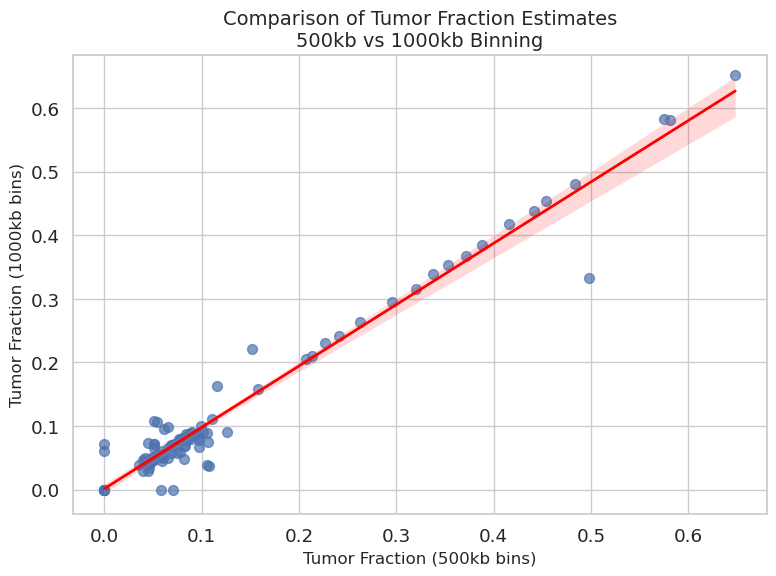

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

# Load and extract only relevant columns
tfx_500kb = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/TFx_hg38_500kb_ILC.csv', usecols=['Sample_ID_TP_number', 'Tumor_fraction'])
tfx_1000kb = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/TFx_hg38_1000kb_ILC.csv', usecols=['Sample_ID_TP_number', 'Tumor_fraction'])

# Rename for clarity
tfx_500kb.rename(columns={'Sample_ID_TP_number': 'Sample', 'Tumor_fraction': 'TFx_500kb'}, inplace=True)
tfx_1000kb.rename(columns={'Sample_ID_TP_number': 'Sample', 'Tumor_fraction': 'TFx_1000kb'}, inplace=True)

# Strip whitespace from sample IDs
tfx_500kb['Sample'] = tfx_500kb['Sample'].str.strip()
tfx_1000kb['Sample'] = tfx_1000kb['Sample'].str.strip()

# Merge
tfx_merged = pd.merge(tfx_500kb, tfx_1000kb, on='Sample', how='inner')

# Save merged data
tfx_merged.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/tfx_500kb_vs_1000kb.csv', index=False)

# Correlation
pearson_corr = pearsonr(tfx_merged['TFx_500kb'], tfx_merged['TFx_1000kb'])
spearman_corr = spearmanr(tfx_merged['TFx_500kb'], tfx_merged['TFx_1000kb'])

print(f"🔹 Pearson r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.2e}")
print(f"🔹 Spearman rho = {spearman_corr.correlation:.4f}, p = {spearman_corr.pvalue:.2e}")

# Regression for reference
X = sm.add_constant(tfx_merged['TFx_500kb'])
y = tfx_merged['TFx_1000kb']
model = sm.OLS(y, X).fit()

# Plot
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8,6))
sns.regplot(
    data=tfx_merged,
    x='TFx_500kb',
    y='TFx_1000kb',
    scatter_kws={'s': 50, 'alpha': 0.7},
    line_kws={'color': 'red', 'lw': 2}
)
plt.xlabel('Tumor Fraction (500kb bins)', fontsize=12)
plt.ylabel('Tumor Fraction (1000kb bins)', fontsize=12)
plt.title('Comparison of Tumor Fraction Estimates\n500kb vs 1000kb Binning', fontsize=14)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/TFx_500kb_vs_1000kb_plot.png', dpi=300)

# Print regression summary
print(model.summary())

# --------------------------------------------
# Save correlation and regression stats to CSV
# --------------------------------------------
stats_summary = {
    'Pearson_r': [pearson_corr[0]],
    'Pearson_p': [pearson_corr[1]],
    'Spearman_rho': [spearman_corr.correlation],
    'Spearman_p': [spearman_corr.pvalue],
    'OLS_Intercept': [model.params['const']],
    'OLS_Slope': [model.params['TFx_500kb']],
    'OLS_p_value': [model.pvalues['TFx_500kb']],
    'R_squared': [model.rsquared],
    'Adj_R_squared': [model.rsquared_adj]
}

stats_df = pd.DataFrame(stats_summary)

# Save to file
stats_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/tfx_bin_comparison_stats.csv', index=False)
print("\n Stats saved to tfx_bin_comparison_stats.csv")


🔎 Found 10 samples with TFx(1000kb) - TFx(500kb) > 0.05


count    10.000000
mean      0.103604
std       0.118880
min       0.029030
25%       0.035366
50%       0.072247
75%       0.079805
max       0.415300
Name: TFx_avg, dtype: float64

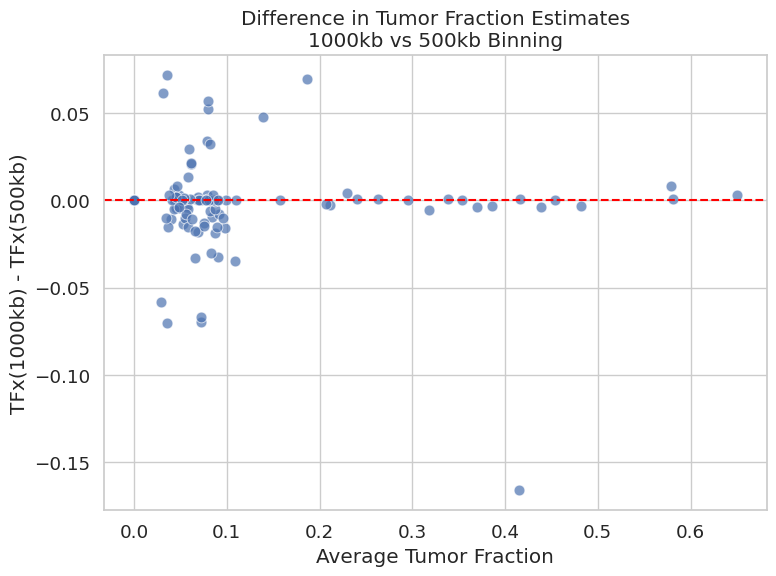

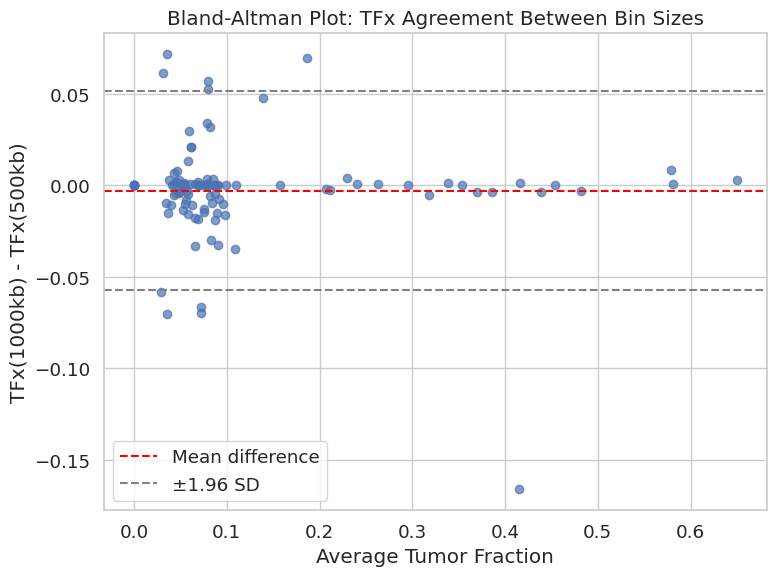

In [29]:
tfx_merged['TFx_diff'] = tfx_merged['TFx_1000kb'] - tfx_merged['TFx_500kb']
# Compute average TFx per sample
tfx_merged['TFx_avg'] = (tfx_merged['TFx_500kb'] + tfx_merged['TFx_1000kb']) / 2

# Scatterplot
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.scatterplot(data=tfx_merged, x='TFx_avg', y='TFx_diff', alpha=0.7, s=60)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Average Tumor Fraction')
plt.ylabel('TFx(1000kb) - TFx(500kb)')
plt.title('Difference in Tumor Fraction Estimates\n1000kb vs 500kb Binning')
plt.grid(True)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/TFx_bin_difference_vs_avgTFx.png', dpi=300)

# Absolute difference > 0.05
large_diff = tfx_merged[abs(tfx_merged['TFx_diff']) > 0.05]

# Save list
large_diff.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/samples_with_large_TFx_disagreement.csv', index=False)

print(f"🔎 Found {len(large_diff)} samples with TFx(1000kb) - TFx(500kb) > 0.05")


# Bland-Altman, To assess agreement and bias
mean = tfx_merged['TFx_avg']
diff = tfx_merged['TFx_diff']

plt.figure(figsize=(8,6))
plt.scatter(mean, diff, alpha=0.7)
plt.axhline(diff.mean(), color='red', linestyle='--', label='Mean difference')
plt.axhline(diff.mean() + 1.96*diff.std(), color='gray', linestyle='--', label='±1.96 SD')
plt.axhline(diff.mean() - 1.96*diff.std(), color='gray', linestyle='--')
plt.xlabel('Average Tumor Fraction')
plt.ylabel('TFx(1000kb) - TFx(500kb)')
plt.title('Bland-Altman Plot: TFx Agreement Between Bin Sizes')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/500vs1000kb_bin/bland_altman_TFx_bin_comparison.png', dpi=300)

# Where do these samples fall in TFx range
large_diff['TFx_avg'].describe()

In [32]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------
# File paths
# ---------------------------------------
frag_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/Global_fragment_size_proportions.csv'
tf_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_500kb_ILC.csv'

# Load data
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)

# Optional: Check column names
print(frag_df.columns)
print(tf_df.columns)


Index(['Sample', 'Subnucleosomal_90_150', 'Mononucleosomal_151_250',
       'Dinucleosomal_251_450', 'Trinucleosomal_451_650'],
      dtype='object')
Index(['Case_ID', 'Sample_ID_TP_number', 'Draw_Number', 'Timepoint',
       'Tumor_fraction', 'Ploidy', 'Subclonal_fraction',
       'Frac_Genome_Subclonal', 'Frac_CNA_Subclonal'],
      dtype='object')


In [33]:
# ---------------------------------------
# Step 1: Load and clean data
# ---------------------------------------
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)

# Standardize column names for merging
frag_df.rename(columns={'Sample_ID_TP_number': 'Sample'}, inplace=True)
tf_df.rename(columns={'Sample_ID_TP_number': 'Sample', 'Tumor_fraction_500kb bin': 'Tumor_fraction'}, inplace=True)

# Strip any whitespace
frag_df['Sample'] = frag_df['Sample'].astype(str).str.strip()
tf_df['Sample'] = tf_df['Sample'].astype(str).str.strip()

# ---------------------------------------
# Step 2: Sample comparison
# ---------------------------------------
frag_samples = set(frag_df['Sample'].dropna().unique())
tf_samples = set(tf_df['Sample'].dropna().unique())

matched_samples = frag_samples & tf_samples
only_in_frag = frag_samples - tf_samples
only_in_tf = tf_samples - frag_samples

# ---------------------------------------
# Step 3: Print counts
# ---------------------------------------
print(f" Total samples in fragmentation file: {len(frag_samples)}")
print(f" Total samples in TFx file:           {len(tf_samples)}")
print(f" Matched samples in both:             {len(matched_samples)}")
print(f" Samples only in fragmentation file:  {len(only_in_frag)}")
print(f" Samples only in TFx file:            {len(only_in_tf)}")

# ---------------------------------------
# Step 4: Save unmatched samples (optional)
# ---------------------------------------
pd.DataFrame(sorted(only_in_frag), columns=['Unmatched_in_TFx']).to_csv('only_in_fragmentation.csv', index=False)
pd.DataFrame(sorted(only_in_tf), columns=['Unmatched_in_fragmentation']).to_csv('only_in_tfx.csv', index=False)

# ---------------------------------------
# Step 5: Print unmatched sample list (if any)
# ---------------------------------------
if only_in_frag:
    print("\nSamples only in fragmentation file (missing in TFx):")
    for s in sorted(only_in_frag):
        print(f" - {s}")
else:
    print("\n All fragmentation samples are present in TFx file.")

 Total samples in fragmentation file: 112
 Total samples in TFx file:           112
 Matched samples in both:             112
 Samples only in fragmentation file:  0
 Samples only in TFx file:            0

 All fragmentation samples are present in TFx file.


In [41]:
# Merge and export the final dataset
merged_df = pd.merge(tf_df, frag_df, on='Sample', how='inner')

# Optional: sort for readability
merged_df = merged_df.sort_values(by='Tumor_fraction', ascending=False)

# Save
merged_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/merged_TFx_hg38_500kb_fragmentation.csv', index=False)

print(f"Merged dataset saved")

Merged dataset saved


In [42]:
from scipy.stats import pearsonr, spearmanr

# Basic correlation (linear and rank-based)
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

print(f" Pearson correlation: r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.4e}")
print(f" Spearman correlation: rho = {spearman_corr.correlation:.4f}, p = {spearman_corr.pvalue:.4e}")


 Pearson correlation: r = 0.4587, p = 3.6580e-07
 Spearman correlation: rho = 0.2287, p = 1.5307e-02


In [43]:
import statsmodels.api as sm

# Prepare regression inputs
X = merged_df['Tumor_fraction']
y = merged_df['Subnucleosomal_90_150']
X = sm.add_constant(X)  # Adds intercept

# Fit model
model = sm.OLS(y, X).fit()
print(model.summary())


                              OLS Regression Results                             
Dep. Variable:     Subnucleosomal_90_150   R-squared:                       0.210
Model:                               OLS   Adj. R-squared:                  0.203
Method:                    Least Squares   F-statistic:                     29.31
Date:                   Thu, 16 Oct 2025   Prob (F-statistic):           3.66e-07
Time:                           11:57:38   Log-Likelihood:                 186.36
No. Observations:                    112   AIC:                            -368.7
Df Residuals:                        110   BIC:                            -363.3
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const         


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
Figure: Relationship between tumor fraction (estimated using 500kb bins) and subnucleosomal cfDNA fragmentation. Each point represents a patient plasma sample (n=112). Tumor fraction was estimated using ichorCNA (500kb bin size), and the proportion of short DNA fragments (<150bp) was derived from global cfDNA fragmentation profiles. A moderate positive correlation was observed (Pearson r = 0.4587, p = 3.7e-07), indicating that higher tumor burden is associated with increased cfDNA fragmentation. The regression line is shown in red.
--------------------------------------------------------------------------------


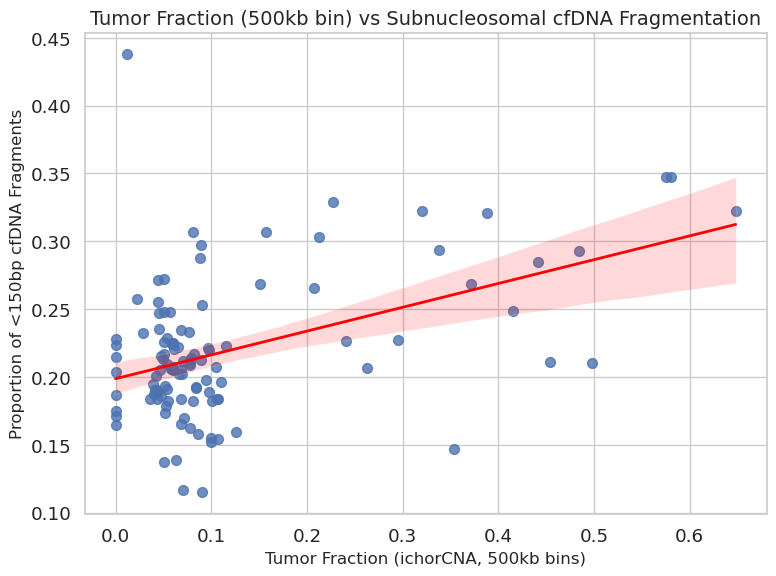

In [49]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

# -----------------------------
# Step 1: Load the merged dataset
# -----------------------------
# Make sure this path points to your cleaned merged file
merged_df = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/merged_TFx_hg38_500kb_fragmentation.csv')

# Optional: clean sample names (if needed)
merged_df['Sample'] = merged_df['Sample'].astype(str).str.strip()

# -----------------------------
# Step 2: Correlation Analysis
# -----------------------------
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

# -----------------------------
# Step 3: OLS Regression
# -----------------------------
X = sm.add_constant(merged_df['Tumor_fraction'])
y = merged_df['Subnucleosomal_90_150']
model = sm.OLS(y, X).fit()

# -----------------------------
# Step 4: Save stats to CSV
# -----------------------------
stats_summary = {
    "Pearson_r": [pearson_corr[0]],
    "Pearson_p": [pearson_corr[1]],
    "Spearman_rho": [spearman_corr.correlation],
    "Spearman_p": [spearman_corr.pvalue],
    "OLS_Intercept": [model.params['const']],
    "OLS_Slope": [model.params['Tumor_fraction']],
    "OLS_p_value": [model.pvalues['Tumor_fraction']],
    "R_squared": [model.rsquared],
    "Adj_R_squared": [model.rsquared_adj]
}
stats_df = pd.DataFrame(stats_summary)
stats_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_500kb_fragmentation_stats.csv', index=False)

# -----------------------------
# Step 5: Generate Publication-Quality Plot
# -----------------------------
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8, 6))
sns.regplot(
    data=merged_df,
    x='Tumor_fraction',
    y='Subnucleosomal_90_150',
    scatter_kws={'s': 50, 'alpha': 0.8},
    line_kws={'color': 'red', 'lw': 2}
)
plt.title('Tumor Fraction (500kb bin) vs Subnucleosomal cfDNA Fragmentation', fontsize=14)
plt.xlabel('Tumor Fraction (ichorCNA, 500kb bins)', fontsize=12)
plt.ylabel('Proportion of <150bp cfDNA Fragments', fontsize=12)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_500kb_vs_fragmentation_plot.png', dpi=300)

# -----------------------------
# Step 6: Print Figure Caption
# -----------------------------
caption = (
    f"Figure: Relationship between tumor fraction (estimated using 500kb bins) and subnucleosomal cfDNA fragmentation. "
    f"Each point represents a patient plasma sample (n={len(merged_df)}). "
    f"Tumor fraction was estimated using ichorCNA (500kb bin size), and the proportion of short DNA fragments (<150bp) "
    f"was derived from global cfDNA fragmentation profiles. "
    f"A moderate positive correlation was observed (Pearson r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.1e}), "
    f"indicating that higher tumor burden is associated with increased cfDNA fragmentation. "
    f"The regression line is shown in red."
)

print("\n" + "-"*80)
print("-"*80)
print(caption)
print("-"*80)


In [50]:
import pandas as pd
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

# ---------------------------------------
# File paths
# ---------------------------------------
frag_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/Global_fragment_size_proportions.csv'
tf_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_1000kb_ILC.csv'

# Load data
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)

# Optional: Check column names
print(frag_df.columns)
print(tf_df.columns)

# ---------------------------------------
# Step 1: Load and clean data
# ---------------------------------------
frag_df = pd.read_csv(frag_path)
tf_df = pd.read_csv(tf_path)

# Standardize column names for merging
frag_df.rename(columns={'Sample_ID_TP_number': 'Sample'}, inplace=True)
tf_df.rename(columns={'Sample_ID_TP_number': 'Sample', 'Tumor_fraction_500kb bin': 'Tumor_fraction'}, inplace=True)

# Strip any whitespace
frag_df['Sample'] = frag_df['Sample'].astype(str).str.strip()
tf_df['Sample'] = tf_df['Sample'].astype(str).str.strip()

# ---------------------------------------
# Step 2: Sample comparison
# ---------------------------------------
frag_samples = set(frag_df['Sample'].dropna().unique())
tf_samples = set(tf_df['Sample'].dropna().unique())

matched_samples = frag_samples & tf_samples
only_in_frag = frag_samples - tf_samples
only_in_tf = tf_samples - frag_samples

# ---------------------------------------
# Step 3: Print counts
# ---------------------------------------
print(f" Total samples in fragmentation file: {len(frag_samples)}")
print(f" Total samples in TFx file:           {len(tf_samples)}")
print(f" Matched samples in both:             {len(matched_samples)}")
print(f" Samples only in fragmentation file:  {len(only_in_frag)}")
print(f" Samples only in TFx file:            {len(only_in_tf)}")

# ---------------------------------------
# Step 4: Save unmatched samples (optional)
# ---------------------------------------
pd.DataFrame(sorted(only_in_frag), columns=['Unmatched_in_TFx']).to_csv('only_in_fragmentation.csv', index=False)
pd.DataFrame(sorted(only_in_tf), columns=['Unmatched_in_fragmentation']).to_csv('only_in_tfx.csv', index=False)

# ---------------------------------------
# Step 5: Print unmatched sample list (if any)
# ---------------------------------------
if only_in_frag:
    print("\nSamples only in fragmentation file (missing in TFx):")
    for s in sorted(only_in_frag):
        print(f" - {s}")
else:
    print("\n All fragmentation samples are present in TFx file.")

Index(['Sample', 'Subnucleosomal_90_150', 'Mononucleosomal_151_250',
       'Dinucleosomal_251_450', 'Trinucleosomal_451_650'],
      dtype='object')
Index(['Case_ID', 'Sample_ID_TP_number', 'Draw_Number', 'Timepoint',
       'Tumor_fraction', 'Ploidy', 'Subclonal_fraction',
       'Frac_Genome_Subclonal', 'Frac_CNA_Subclonal'],
      dtype='object')
 Total samples in fragmentation file: 112
 Total samples in TFx file:           112
 Matched samples in both:             112
 Samples only in fragmentation file:  0
 Samples only in TFx file:            0

 All fragmentation samples are present in TFx file.


In [51]:
# Merge and export the final dataset
merged_df = pd.merge(tf_df, frag_df, on='Sample', how='inner')

# Optional: sort for readability
merged_df = merged_df.sort_values(by='Tumor_fraction', ascending=False)

# Save
merged_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/merged_TFx_hg38_1000kb_fragmentation.csv', index=False)

print(f"Merged dataset saved")

Merged dataset saved


In [52]:
from scipy.stats import pearsonr, spearmanr

# Basic correlation (linear and rank-based)
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

print(f" Pearson correlation: r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.4e}")
print(f" Spearman correlation: rho = {spearman_corr.correlation:.4f}, p = {spearman_corr.pvalue:.4e}")


 Pearson correlation: r = 0.4824, p = 7.2048e-08
 Spearman correlation: rho = 0.2567, p = 6.2981e-03


In [53]:
import statsmodels.api as sm

# Prepare regression inputs
X = merged_df['Tumor_fraction']
y = merged_df['Subnucleosomal_90_150']
X = sm.add_constant(X)  # Adds intercept

# Fit model
model = sm.OLS(y, X).fit()
print(model.summary())


                              OLS Regression Results                             
Dep. Variable:     Subnucleosomal_90_150   R-squared:                       0.233
Model:                               OLS   Adj. R-squared:                  0.226
Method:                    Least Squares   F-statistic:                     33.36
Date:                   Thu, 16 Oct 2025   Prob (F-statistic):           7.20e-08
Time:                           12:00:07   Log-Likelihood:                 187.97
No. Observations:                    112   AIC:                            -371.9
Df Residuals:                        110   BIC:                            -366.5
Df Model:                              1                                         
Covariance Type:               nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const         


--------------------------------------------------------------------------------
--------------------------------------------------------------------------------
Figure: Relationship between tumor fraction (estimated using 1000kb bins) and subnucleosomal cfDNA fragmentation. Each point represents a patient plasma sample (n=112). Tumor fraction was estimated using ichorCNA (500kb bin size), and the proportion of short DNA fragments (<150bp) was derived from global cfDNA fragmentation profiles. A moderate positive correlation was observed (Pearson r = 0.4824, p = 7.2e-08), indicating that higher tumor burden is associated with increased cfDNA fragmentation. The regression line is shown in red.
--------------------------------------------------------------------------------


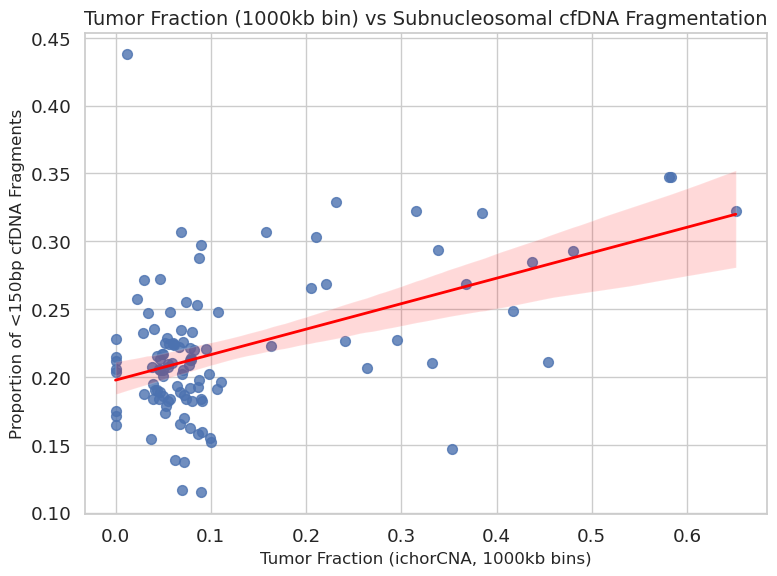

In [59]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
import statsmodels.api as sm

# -----------------------------
# Step 1: Load the merged dataset
# -----------------------------
# Make sure this path points to your cleaned merged file
merged_df = pd.read_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/merged_TFx_hg38_1000kb_fragmentation.csv')

# Optional: clean sample names (if needed)
merged_df['Sample'] = merged_df['Sample'].astype(str).str.strip()

# -----------------------------
# Step 2: Correlation Analysis
# -----------------------------
pearson_corr = pearsonr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])
spearman_corr = spearmanr(merged_df['Tumor_fraction'], merged_df['Subnucleosomal_90_150'])

# -----------------------------
# Step 3: OLS Regression
# -----------------------------
X = sm.add_constant(merged_df['Tumor_fraction'])
y = merged_df['Subnucleosomal_90_150']
model = sm.OLS(y, X).fit()

# -----------------------------
# Step 4: Save stats to CSV
# -----------------------------
stats_summary = {
    "Pearson_r": [pearson_corr[0]],
    "Pearson_p": [pearson_corr[1]],
    "Spearman_rho": [spearman_corr.correlation],
    "Spearman_p": [spearman_corr.pvalue],
    "OLS_Intercept": [model.params['const']],
    "OLS_Slope": [model.params['Tumor_fraction']],
    "OLS_p_value": [model.pvalues['Tumor_fraction']],
    "R_squared": [model.rsquared],
    "Adj_R_squared": [model.rsquared_adj]
}
stats_df = pd.DataFrame(stats_summary)
stats_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_1000kb_fragmentation_stats.csv', index=False)

# -----------------------------
# Step 5: Generate Publication-Quality Plot
# -----------------------------
sns.set(style="whitegrid", font_scale=1.2)
plt.figure(figsize=(8, 6))
sns.regplot(
    data=merged_df,
    x='Tumor_fraction',
    y='Subnucleosomal_90_150',
    scatter_kws={'s': 50, 'alpha': 0.8},
    line_kws={'color': 'red', 'lw': 2}
)
plt.title('Tumor Fraction (1000kb bin) vs Subnucleosomal cfDNA Fragmentation', fontsize=14)
plt.xlabel('Tumor Fraction (ichorCNA, 1000kb bins)', fontsize=12)
plt.ylabel('Proportion of <150bp cfDNA Fragments', fontsize=12)
plt.tight_layout()
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_1000kb_vs_fragmentation_plot.png', dpi=300)

# -----------------------------
# Step 6: Print Figure Caption
# -----------------------------
caption = (
    f"Figure: Relationship between tumor fraction (estimated using 1000kb bins) and subnucleosomal cfDNA fragmentation. "
    f"Each point represents a patient plasma sample (n={len(merged_df)}). "
    f"Tumor fraction was estimated using ichorCNA (500kb bin size), and the proportion of short DNA fragments (<150bp) "
    f"was derived from global cfDNA fragmentation profiles. "
    f"A moderate positive correlation was observed (Pearson r = {pearson_corr[0]:.4f}, p = {pearson_corr[1]:.1e}), "
    f"indicating that higher tumor burden is associated with increased cfDNA fragmentation. "
    f"The regression line is shown in red."
)

print("\n" + "-"*80)
print("-"*80)
print(caption)
print("-"*80)


 Total samples in fragmentation file: 112
 Total samples in TFx file:           112
 Matched samples in both:             112
 Only in fragmentation:               0
 Only in TFx:                         0
 Merged dataset shape: (112, 6)
 Correlation analysis complete. Saved to fragmentation_vs_TFx_correlations.csv


/software/rhel9/manual/install/python/ondemand-jupyter-python3.11-2023.09/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


 Plot saved to fragmentation_vs_TFx_plot.png


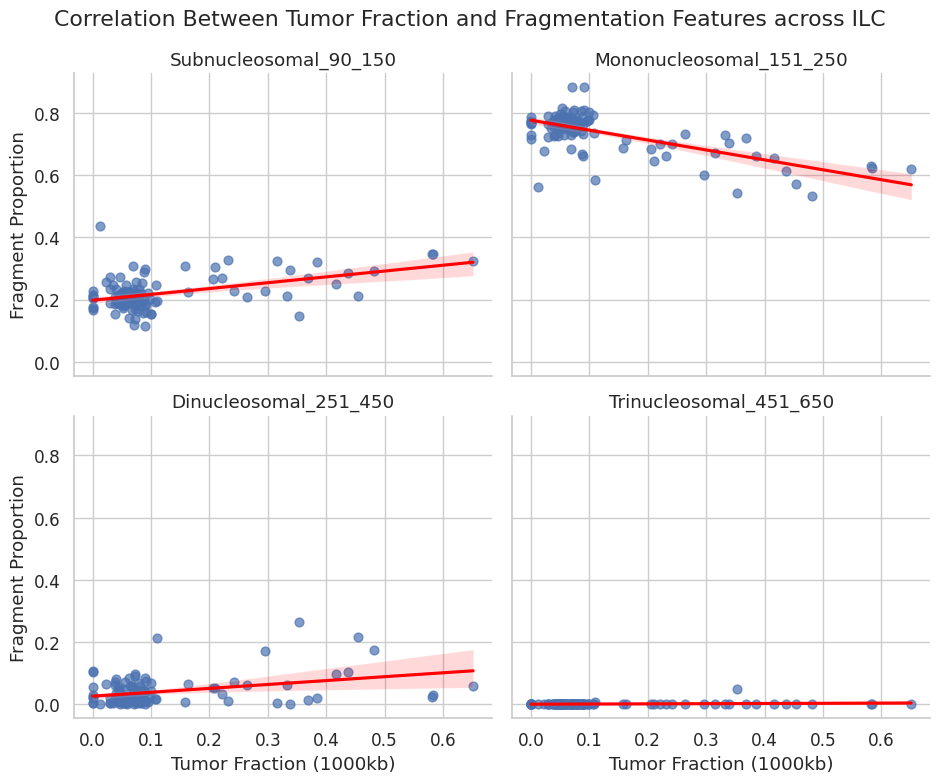

In [60]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

# -------------------------
# Step 1: Load and Clean Data
# -------------------------

# Load fragmentation proportions
frag_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/Global_fragment_size_proportions.csv'
frag_df = pd.read_csv(frag_path)

# Rename sample column if needed
if 'Sample_ID_TP_number' in frag_df.columns:
    frag_df.rename(columns={'Sample_ID_TP_number': 'Sample'}, inplace=True)

# Load TFx (1000kb)
tfx_path = '/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/TFx_hg38_1000kb_ILC.csv'
tfx_df = pd.read_csv(tfx_path)

# Rename and clean
tfx_df = tfx_df[['Sample_ID_TP_number', 'Tumor_fraction']].copy()
tfx_df.rename(columns={'Sample_ID_TP_number': 'Sample'}, inplace=True)

frag_df['Sample'] = frag_df['Sample'].astype(str).str.strip()
tfx_df['Sample'] = tfx_df['Sample'].astype(str).str.strip()

# -------------------------
# Step 2: Sample Consistency Check
# -------------------------

# Optional sample consistency check (prints + saves mismatches)
frag_samples = set(frag_df['Sample'].dropna().unique())
tfx_samples = set(tfx_df['Sample'].dropna().unique())

only_in_frag = frag_samples - tfx_samples
only_in_tfx = tfx_samples - frag_samples

print(f" Total samples in fragmentation file: {len(frag_samples)}")
print(f" Total samples in TFx file:           {len(tfx_samples)}")
print(f" Matched samples in both:             {len(frag_samples & tfx_samples)}")
print(f" Only in fragmentation:               {len(only_in_frag)}")
print(f" Only in TFx:                         {len(only_in_tfx)}")

# Save unmatched samples
pd.DataFrame(sorted(only_in_frag), columns=['Unmatched_in_TFx']).to_csv('only_in_fragmentation.csv', index=False)
pd.DataFrame(sorted(only_in_tfx), columns=['Unmatched_in_fragmentation']).to_csv('only_in_tfx.csv', index=False)

# -------------------------
# Step 3: Merge Datasets
# -------------------------

# Merge on shared samples only
merged_df = pd.merge(tfx_df, frag_df, on='Sample', how='inner')
print(f" Merged dataset shape: {merged_df.shape}")

# -------------------------
# Step 4: Correlation Analysis
# -------------------------

fragment_features = [
    'Subnucleosomal_90_150',
    'Mononucleosomal_151_250',
    'Dinucleosomal_251_450',
    'Trinucleosomal_451_650'
]

correlation_results = []

for feature in fragment_features:
    pearson_r, pearson_p = pearsonr(merged_df['Tumor_fraction'], merged_df[feature])
    spearman_rho, spearman_p = spearmanr(merged_df['Tumor_fraction'], merged_df[feature])
    correlation_results.append({
        'Fragment_feature': feature,
        'Pearson_r': pearson_r,
        'Pearson_p': pearson_p,
        'Spearman_rho': spearman_rho,
        'Spearman_p': spearman_p
    })

# Save correlation results
corr_df = pd.DataFrame(correlation_results)
corr_df.to_csv('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/fragmentation_vs_TFx_correlations.csv', index=False)
print(" Correlation analysis complete. Saved to fragmentation_vs_TFx_correlations.csv")

# -------------------------
# Step 5: Plotting
# -------------------------

# Prepare for multi-panel plot
long_df = merged_df.melt(
    id_vars='Tumor_fraction',
    value_vars=fragment_features,
    var_name='Fragment_Type',
    value_name='Proportion'
)

# Plot
sns.set(style="whitegrid", font_scale=1.1)
g = sns.lmplot(
    data=long_df,
    x='Tumor_fraction',
    y='Proportion',
    col='Fragment_Type',
    col_wrap=2,
    height=4,
    aspect=1.2,
    scatter_kws={'s': 40, 'alpha': 0.7},
    line_kws={'color': 'red'}
)
g.set_titles('{col_name}')
g.set_axis_labels("Tumor Fraction (1000kb)", "Fragment Proportion")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Correlation Between Tumor Fraction and Fragmentation Features across ILC")
plt.savefig('/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/ILC/Corelation/Global_500_1000kb_bin/fragmentation_vs_TFx_plot.png', dpi=300)

print(" Plot saved to fragmentation_vs_TFx_plot.png")
